<a href="https://colab.research.google.com/github/Storm00212/Signals-and-communication-visualisation/blob/main/visualisation_of_exponent_into_cosine_and_sine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:21: SyntaxWarning: invalid escape sequence '\c'
<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:24: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\c'
<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:24: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_1290/1663337846.py:21: SyntaxWarning: invalid escape sequence '\c'
  ax.set_xlabel('Real Axis: $\cos(\omega t)$', fontsize=11, labelpad=10)
/tmp/ipykernel_1290/1663337846.py:22: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('Imaginary Axis: $\sin(\omega t)$', fontsize=11, labelpad=10)
/tmp/ipykernel_1290/1663337846.py:24: SyntaxWarning: invalid escape sequence '\o'
  ax.set_title('3D Complex Exponential Helix Plot ($e^{j\omega t}$)', fontsize=14, weight='bold')


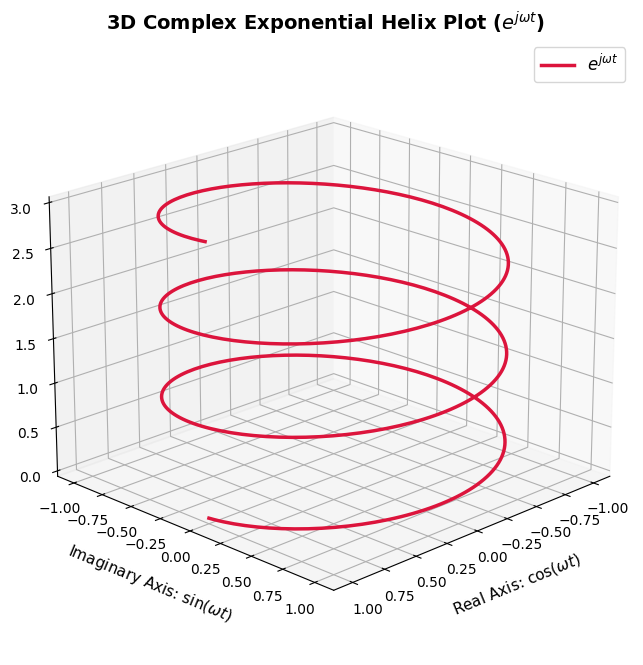

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
f = 1.0          # Frequency in Hz
w = 2 * np.pi * f # Angular frequency (omega)
t = np.linspace(0, 3, 500) # Time vector for 3 full periods

# Compute components
real_part = np.cos(w * t)
imag_part = np.sin(w * t)

# Initialize 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the 3D spiral (helix)
ax.plot(real_part, imag_part, t, color='crimson', lw=2.5, label=r'$e^{j\omega t}$')

# Aesthetic adjustments and labeling
ax.set_xlabel('Real Axis: $\cos(\omega t)$', fontsize=11, labelpad=10)
ax.set_ylabel('Imaginary Axis: $\sin(\omega t)$', fontsize=11, labelpad=10)
ax.set_zlabel('Time Axis ($t$)', fontsize=11, labelpad=10)
ax.set_title('3D Complex Exponential Helix Plot ($e^{j\omega t}$)', fontsize=14, weight='bold')

ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', fontsize=12)

# Set an optimal viewing angle
ax.view_init(elev=20, azim=45)

plt.show()


<>:33: SyntaxWarning: invalid escape sequence '\o'
<>:33: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_1290/656280869.py:33: SyntaxWarning: invalid escape sequence '\o'
  ax.set_title('Deconstruction of $e^{j\omega t}$ into Cosine and Sine Shadows', fontsize=14, weight='bold')


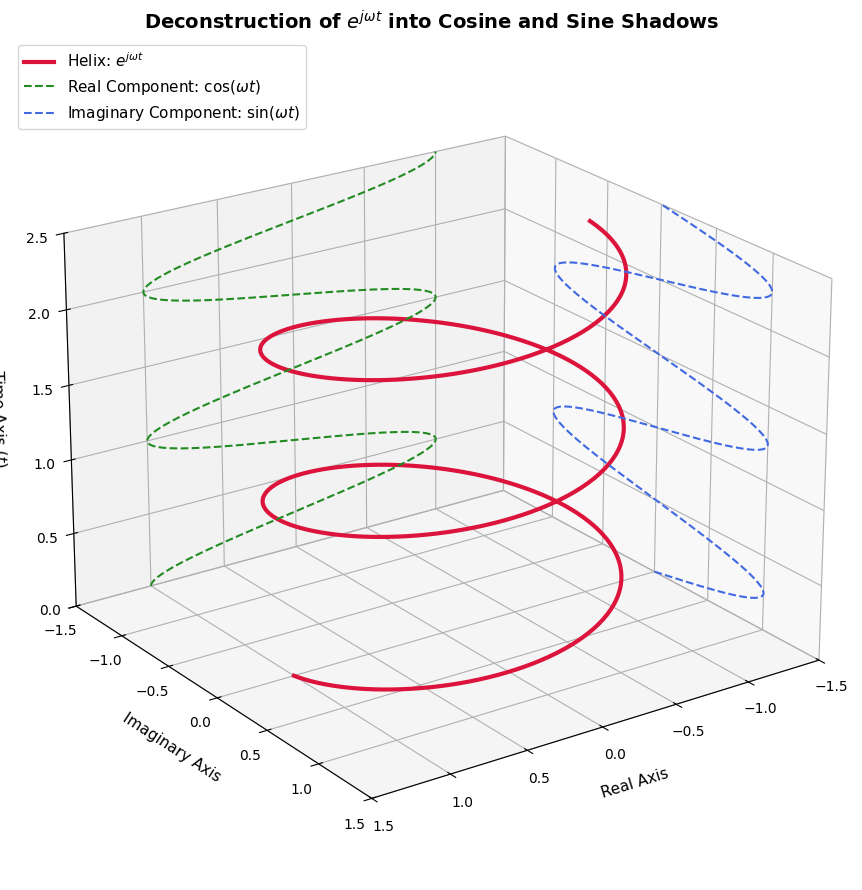

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define Parameters
f = 1.0                     # Frequency in Hz
w = 2 * np.pi * f            # Angular frequency
t = np.linspace(0, 2.5, 600) # Time horizon

# 2. Compute Components
real_cos = np.cos(w * t)
imag_sin = np.sin(w * t)

# 3. Setup Figure & 3D Axis
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# 4. Plot 3D Core Spiral (The Helix)
ax.plot(real_cos, imag_sin, t, color='crimson', lw=3, label=r'Helix: $e^{j\omega t}$')

# 5. Plot Component Shadows (Projections)
# Cosine Component projected onto the Real-Time plane (at Imaginary = -1.5 wall)
ax.plot(real_cos, np.zeros_like(t) - 1.5, t, color='forestgreen', lw=1.5,
        linestyle='--', label=r'Real Component: $\cos(\omega t)$')

# Sine Component projected onto the Imaginary-Time plane (at Real = -1.5 wall)
ax.plot(np.zeros_like(t) - 1.5, imag_sin, t, color='royalblue', lw=1.5,
        linestyle='--', label=r'Imaginary Component: $\sin(\omega t)$')

# 6. Aesthetic Formatting
ax.set_xlabel('Real Axis', fontsize=11, labelpad=10)
ax.set_ylabel('Imaginary Axis', fontsize=11, labelpad=10)
ax.set_zlabel('Time Axis ($t$)', fontsize=11, labelpad=10)
ax.set_title('Deconstruction of $e^{j\omega t}$ into Cosine and Sine Shadows', fontsize=14, weight='bold')

# Lock axis limits to keep shadows on the outer boundaries
ax.set_xlim([-1.5, 1.5])
ax.set_ylim([-1.5, 1.5])
ax.set_zlim([0, 2.5])

ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', fontsize=11)
ax.view_init(elev=22, azim=55) # Best angle to see both shadows and helix depth

plt.tight_layout()
plt.show()


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import math
from IPython.display import HTML

# 1. Setup Canvas and Plot Parameters
w = 2.0                     # Angular frequency
t = np.linspace(-3, 3, 500) # Time vector centered at 0
true_helix = np.exp(1j * w * t)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

# Draw a static faint gray baseline of the perfect target helix
ax.plot(true_helix.real, true_helix.imag, t, color='gray', alpha=0.2, linestyle='--')

# Initialize empty line and text elements for animation frames
line, = ax.plot([], [], [], color='darkorange', lw=2.5)
title_text = ax.text2D(0.05, 0.95, "", transform=ax.transAxes, fontsize=11, weight='bold')

# Configure clean boundaries and viewing angle
ax.set_xlim([-2.5, 2.5])
ax.set_ylim([-2.5, 2.5])
ax.set_zlim([-3, 3])
ax.set_xlabel('Real Axis')
ax.set_ylabel('Imaginary Axis')
ax.set_zlabel('Time ($t$)')
ax.view_init(elev=20, azim=65)

# 2. Cumulative Taylor Series Math Function
def compute_taylor(t, w, k_max):
    approx = np.zeros_like(t, dtype=complex)
    for n in range(k_max + 1):
        approx += ((1j * w * t) ** n) / math.factorial(n)
    return approx

# 3. Animation Frame Updater
def update_frame(frame_num):
    current_terms = frame_num + 1 # Terms scale from 1 to 22
    approx_data = compute_taylor(t, w, current_terms)

    # Update line positions in 3D space
    line.set_xdata(approx_data.real)
    line.set_ydata(approx_data.imag)
    line.set_3d_properties(t)

    title_text.set_text(f"Taylor Series Terms (N) = {current_terms}")
    return line, title_text

# 4. Generate the Animation Engine
# We use 22 frames to show deep convergence across the entire time block
ani = animation.FuncAnimation(fig, update_frame, frames=22, interval=350, blit=False)
plt.close() # Prevents Colab from displaying an extra broken static plot image

# 5. Render directly inside Colab as an HTML5 Video Controller
HTML(ani.to_jshtml())
